Selected clusters: ['School 3' 'School 8' 'School 4']
       School  Student_ID  Marks
100  School 3         101     39
101  School 3         102     48
102  School 3         103     61
103  School 3         104     43
104  School 3         105     49
105  School 3         106     76
106  School 3         107     85
107  School 3         108     97
108  School 3         109     86
109  School 3         110     38
Total students selected: 150


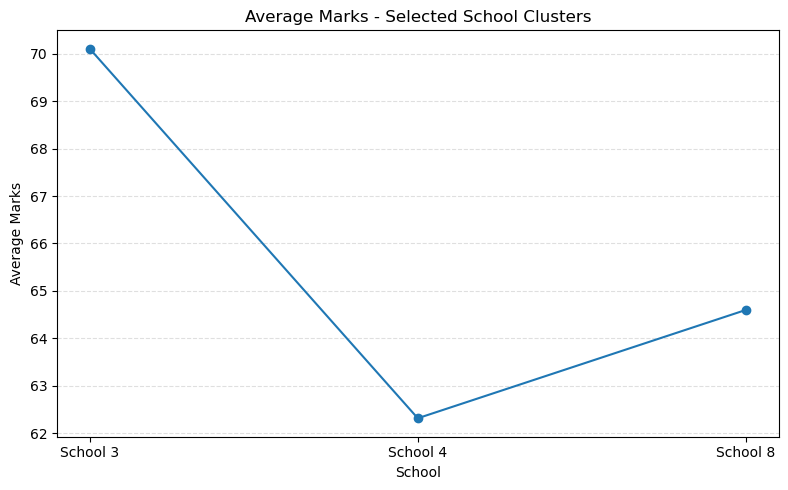

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

# Create 10 schools, with 50 students per school
df = pd.DataFrame({
    "School": np.repeat(
        [f"School {i}" for i in range(1, 11)], 50
    ),
    "Student_ID": range(1, 501),
    "Marks": np.random.randint(35, 101, size=500)
})

# Randomly select 3 schools (clusters)
selected_schools = np.random.choice(
    df["School"].unique(),
    size=3,
    replace=False
)

sample = df[df["School"].isin(selected_schools)]

print("Selected clusters:", selected_schools)
print(sample.head(10))
print("Total students selected:", len(sample))

# Average marks per selected school
avg_marks = sample.groupby("School")["Marks"].mean()

# Line chart
plt.figure(figsize=(8, 5))
plt.plot(avg_marks.index, avg_marks.values, marker="o")
plt.title("Average Marks - Selected School Clusters")
plt.xlabel("School")
plt.ylabel("Average Marks")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("clutser")
plt.show()


Python project with all four libraries

Selected schools: ['School 3' 'School 8' 'School 4']
Number of students: 150
       School  Student_ID  Marks
100  School 3         101     39
101  School 3         102     48
102  School 3         103     61
103  School 3         104     43
104  School 3         105     49
Mean marks: 65.67333333333333
Standard deviation: 19.33335146184447
Skewness: 0.019620384214105176


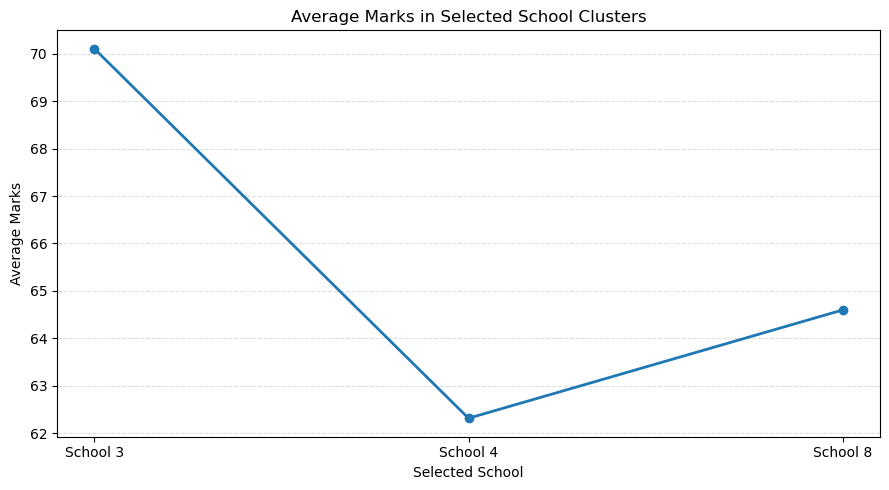

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# 1. Create sample data
np.random.seed(42)
df = pd.DataFrame({
    "School": np.repeat(
        [f"School {i}" for i in range(1, 11)], 50
    ),
    "Student_ID": range(1, 501),
    "Marks": np.random.randint(35, 101, size=500)
})

# 2. Randomly select 3 school clusters
selected_schools = np.random.choice(
    df["School"].unique(),
    size=3,
    replace=False
)

# 3. Include all students from selected schools
sample = df[df["School"].isin(selected_schools)].copy()

print("Selected schools:", selected_schools)
print("Number of students:", len(sample))
print(sample.head())

# 4. Descriptive statistics using SciPy
print("Mean marks:", stats.tmean(sample["Marks"]))
print("Standard deviation:", stats.tstd(sample["Marks"]))
print("Skewness:", stats.skew(sample["Marks"]))

# 5. Average marks per school
school_avg = (
    sample.groupby("School")["Marks"]
    .mean()
    .sort_index()
)

# 6. Clean line chart
plt.figure(figsize=(9, 5))
plt.plot(
    school_avg.index,
    school_avg.values,
    marker="o",
    linewidth=2
)

plt.title("Average Marks in Selected School Clusters")
plt.xlabel("Selected School")
plt.ylabel("Average Marks")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("3")
plt.show()